In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
import subprocess

# Set this to the location of your downloaded SoLo dataset
DATASET_DIR = Path("path/to/SoLo_dataset")

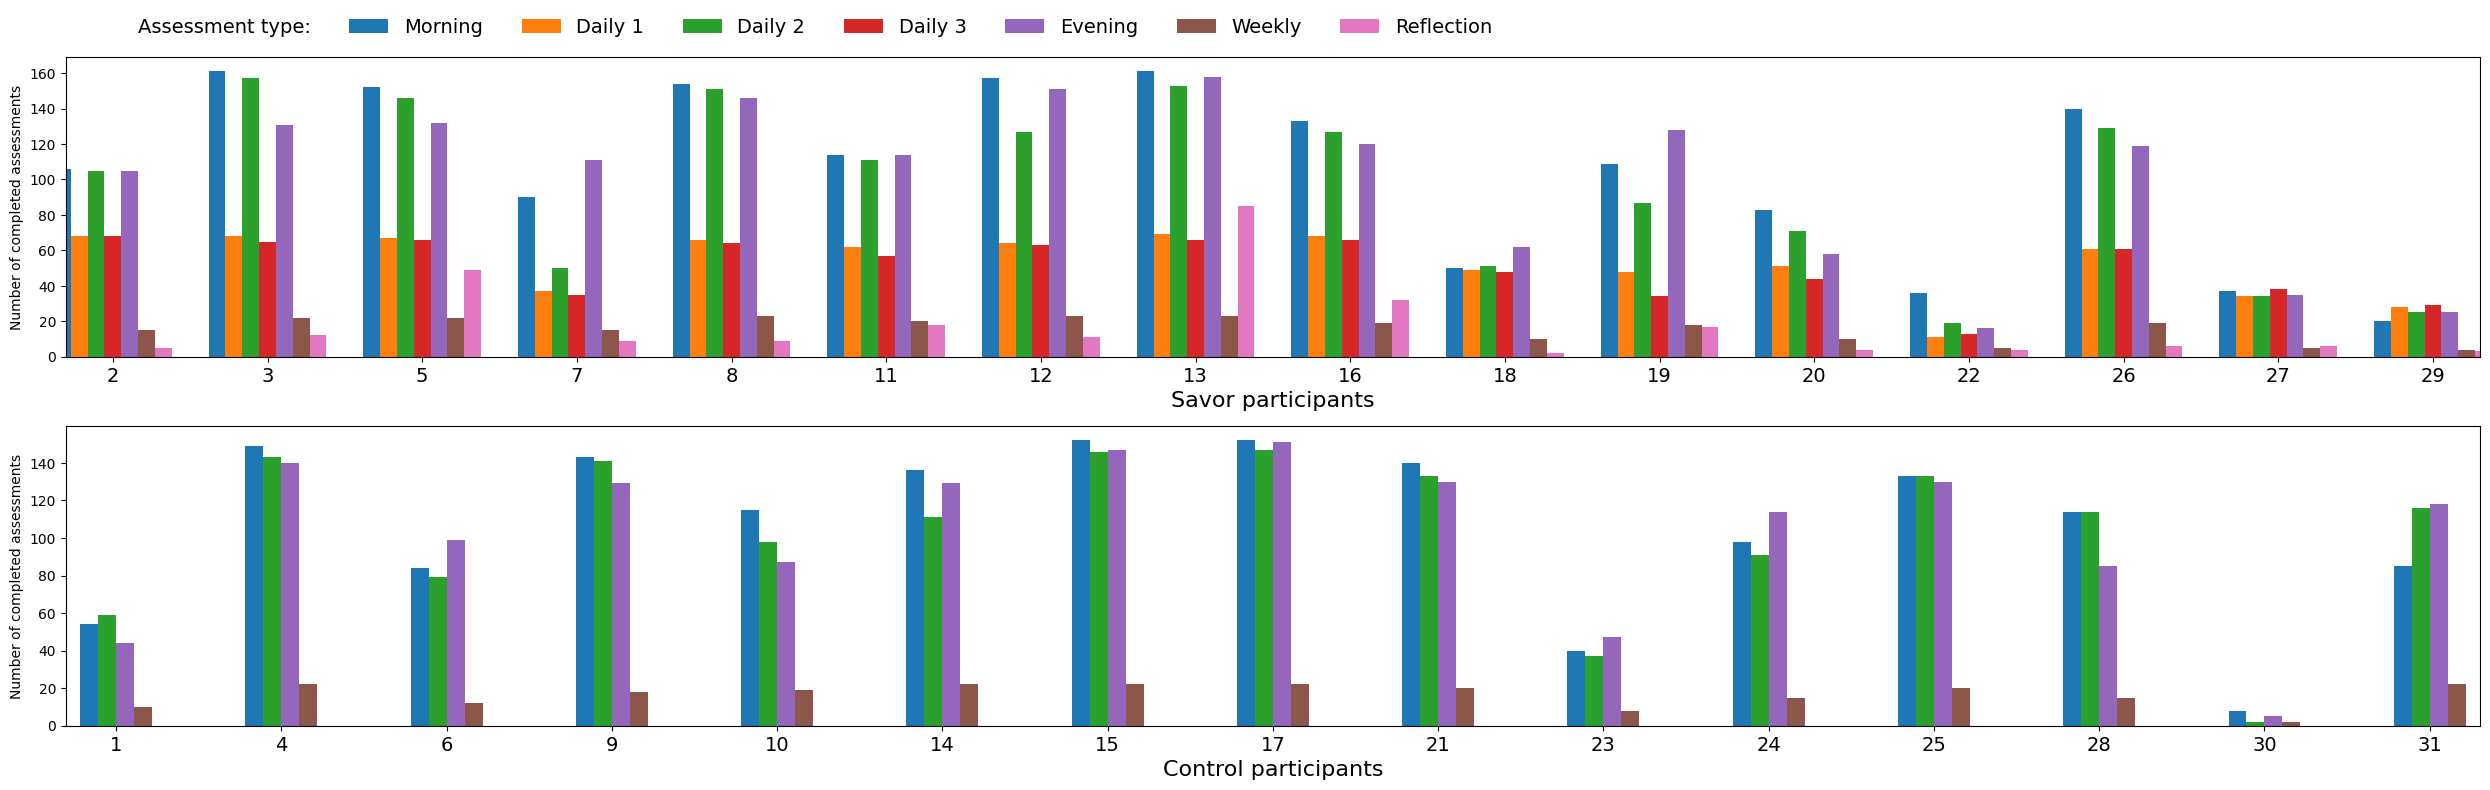

In [17]:
groups = pd.read_csv(DATASET_DIR / "participant_groups.csv")
control = groups.loc[groups["group"] == "control", "participant"].tolist()
savor = groups.loc[groups["group"] == "savor", "participant"].tolist()
participants = control + savor

records = []

for participant in participants:
    self_report = DATASET_DIR / participant / "Self_Report"
    ema_path = self_report / "ema_daily.csv"
    weekly_path = self_report / "weekly_questionnaires.csv"
    reflection_path = self_report / "reflection_activity.csv"

    if ema_path.exists():
        ema = pd.read_csv(ema_path)
        ema_counts = ema["surveyindex"].value_counts()

        records.append({
            "participant": participant,
            "Morning": ema_counts.get(0, 0),
            "Daily 1": ema_counts.get(1, 0),
            "Daily 2": ema_counts.get(2, 0),
            "Daily 3": ema_counts.get(3, 0),
            "Evening": ema_counts.get(4, 0),
            "Weekly": len(pd.read_csv(weekly_path)) if weekly_path.exists() else 0,
            "Reflection": len(pd.read_csv(reflection_path)) if reflection_path.exists() else 0
        })

counts = pd.DataFrame(records).set_index("participant").reindex(participants)

control_types = ["Morning", "Daily 2", "Evening", "Weekly"]
savor_types = ["Morning", "Daily 1", "Daily 2", "Daily 3", "Evening", "Weekly", "Reflection"]

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
assessment_colors = dict(zip(savor_types, colors))

fig, axes = plt.subplots(2, 1, figsize=(25, 8))

# Savoring group
ax = axes[0]
savor_counts = counts.loc[savor]
x = np.arange(len(savor_counts)) * 1.15
width = 0.125

for j, participant in enumerate(savor_counts.index):
    offsets = (np.arange(len(savor_types)) - (len(savor_types) - 1) / 2) * width
    for offset, assessment in zip(offsets, savor_types):
        ax.bar(x[j] + offset, savor_counts.loc[participant, assessment], width, color=assessment_colors[assessment])

ax.set_xlim(x[0] - 0.35, x[-1] + 0.35)
ax.set_xlabel("Savor participants", fontsize=16)
ax.set_ylabel("Number of completed assessments")
ax.set_xticks(x)
ax.set_xticklabels([p.replace("participant_", "") for p in savor_counts.index])
ax.tick_params(axis="x", labelsize=14)

ax.legend(handles=[Patch(facecolor="none", edgecolor="none", label="Assessment type:")] +
            [Patch(facecolor=assessment_colors[a], label=a) for a in savor_types],
    frameon=False, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=8, fontsize=14)

# Control group
ax = axes[1]
control_counts = counts.loc[control]
x = np.arange(len(control_counts)) * 1.15
width = 0.125

for j, participant in enumerate(control_counts.index):
    offsets = (np.arange(len(control_types)) - (len(control_types) - 1) / 2) * width
    for offset, assessment in zip(offsets, control_types):
        ax.bar(x[j] + offset, control_counts.loc[participant, assessment], width, color=assessment_colors[assessment])

ax.set_xlim(x[0] - 0.35, x[-1] + 0.35)
ax.set_xlabel("Control participants", fontsize=16)
ax.set_ylabel("Number of completed assessments")
ax.set_xticks(x)
ax.set_xticklabels([p.replace("participant_", "") for p in control_counts.index])
ax.tick_params(axis="x", labelsize=14)

plt.tight_layout()
plt.show()

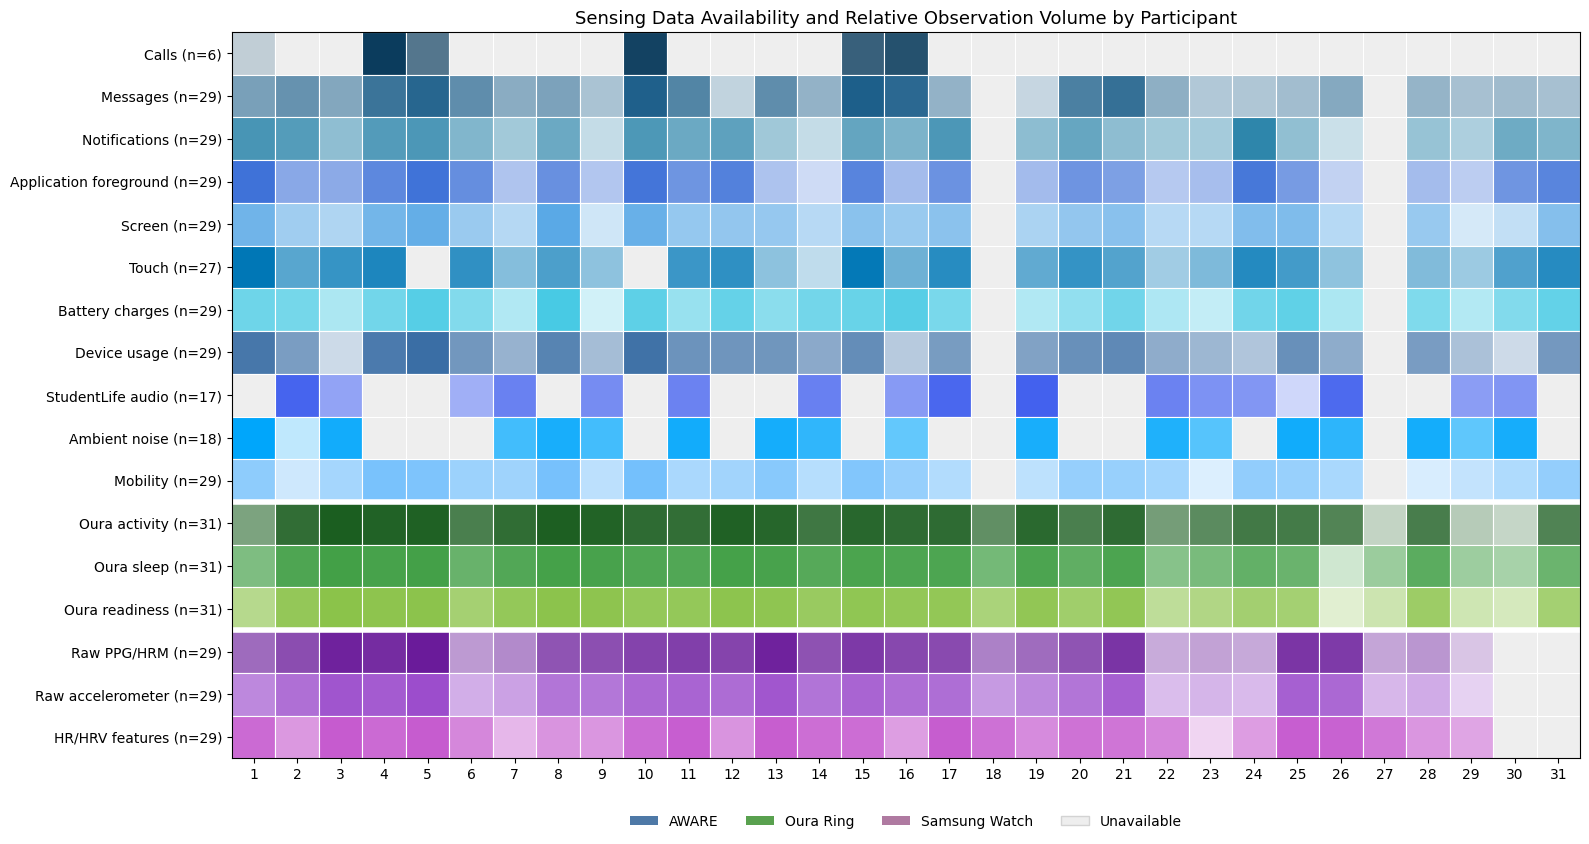

In [13]:
participant_dirs = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()], key=lambda x: int(x.name.replace("participant_", "")))

modalities = ["Calls", "Messages", "Notifications", "Application foreground", "Screen", "Touch", "Battery charges", "Device usage", "StudentLife audio", "Ambient noise", "Mobility", "Oura activity", "Oura sleep", "Oura readiness", "Raw PPG/HRM", "Raw accelerometer", "HR/HRV features"]
row_groups = {"Calls":"AWARE", "Messages":"AWARE", "Notifications":"AWARE", "Application foreground":"AWARE", "Screen":"AWARE", "Touch":"AWARE", "Battery charges":"AWARE", "Device usage":"AWARE", "StudentLife audio":"AWARE", "Ambient noise":"AWARE", "Mobility":"AWARE", "Oura activity":"Oura", "Oura sleep":"Oura", "Oura readiness":"Oura", "Raw PPG/HRM":"Samsung", "Raw accelerometer" : "Samsung", "HR/HRV features":"Samsung"}
row_colors = {"Calls":"#0B3C5D", "Messages":"#1D5F8A", "Notifications":"#2E86AB", "Application foreground":"#3F72D8", "Screen":"#5AA9E6", "Touch":"#0077B6", "Battery charges":"#48CAE4", "Device usage":"#3A6EA5", "StudentLife audio":"#4361EE", "Ambient noise":"#00A6FB", "Mobility":"#74C0FC", "Oura activity":"#1B5E20", "Oura sleep":"#43A047", "Oura readiness":"#8BC34A", "Raw PPG/HRM":"#6A1B9A", "Raw accelerometer":"#9C4DCC", "HR/HRV features":"#C65BCF"}
group_legend_colors = {"AWARE":"#4E79A7", "Oura":"#59A14F", "Samsung":"#AF7AA1"}
unavailable_color = "#EEEEEE"

file_map = {"Calls":["AWARE/calls.csv"], "Messages":["AWARE/messages.csv"], "Notifications":["AWARE/notifications.csv"], 
            "Application foreground":["AWARE/applications_foreground.csv"], "Screen":["AWARE/screen.csv"], 
            "Touch":["AWARE/touch.csv"], "Battery charges":["AWARE/battery_charges.csv"], "Device usage":["AWARE/device_usage.csv"], 
            "StudentLife audio":["AWARE/studentlife_audio.csv"], "Ambient noise":["AWARE/ambient_noise.csv"], 
            "Mobility":["AWARE/mobility_features.csv"], 
            "Oura activity":["Oura/activity_daily.csv"], "Oura sleep":["Oura/sleep_daily.csv"], "Oura readiness":["Oura/readiness_daily.csv"],
            "Raw PPG/HRM":["Samsung/raw_ppg_hrm.csv"], "Raw accelerometer":["Samsung/raw_accelerometer.csv"], "HR/HRV features":["Samsung/hrv_5min.csv"]}

def count_csv_rows(path): return max(int(subprocess.run(["wc", "-l", str(path)], capture_output=True, text=True).stdout.strip().split()[0]) - 1, 0) if path.exists() and path.is_file() else 0

count_df = pd.DataFrame(0, index=modalities, columns=[p.name for p in participant_dirs], dtype=float)

for participant_dir in participant_dirs:
    for modality in modalities:
        count_df.loc[modality, participant_dir.name] = sum(count_csv_rows(participant_dir / relative_path) for relative_path in file_map[modality])

availability_df = (count_df > 0).astype(int)
log_count_df = np.log1p(count_df)
normalized_df = pd.DataFrame(0.0, index=modalities, columns=availability_df.columns)

for modality in modalities:
    positive_log_values = log_count_df.loc[modality][count_df.loc[modality] > 0]
    row_min = positive_log_values.min() if len(positive_log_values) > 0 else 0
    row_max = positive_log_values.max() if len(positive_log_values) > 0 else 0
    normalized_df.loc[modality] = log_count_df.loc[modality].apply(lambda x: 0 if x == 0 else 1 if row_max == row_min else 0.25 + 0.75 * ((x - row_min) / (row_max - row_min)))

fig, ax = plt.subplots(figsize=(16, 8.5))

for i, modality in enumerate(availability_df.index):
    for j, participant in enumerate(availability_df.columns):
        alpha = normalized_df.iloc[i, j]
        color = to_rgba(row_colors[modality], alpha=alpha) if availability_df.iloc[i, j] == 1 else unavailable_color
        ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=color, edgecolor="white", linewidth=0.8))

ax.axhline(11, color="white", linewidth=4)
ax.axhline(14, color="white", linewidth=4)
ax.set_xlim(0, len(availability_df.columns))
ax.set_ylim(len(availability_df.index), 0)
ax.set_xticks(np.arange(len(availability_df.columns)) + 0.5)
ax.set_xticklabels([p.replace("participant_", "") for p in availability_df.columns], rotation=0, fontsize=10)
ax.set_yticks(np.arange(len(availability_df.index)) + 0.5)
ax.set_yticklabels([f"{modality} (n={int(availability_df.loc[modality].sum())})" for modality in availability_df.index], fontsize=10)
ax.set_ylabel("")
ax.set_title("Sensing Data Availability and Relative Observation Volume by Participant", fontsize=13)

legend_handles = [Patch(facecolor=group_legend_colors["AWARE"], label="AWARE"), Patch(facecolor=group_legend_colors["Oura"], label="Oura Ring"), Patch(facecolor=group_legend_colors["Samsung"], label="Samsung Watch"), Patch(facecolor=unavailable_color, edgecolor="lightgray", label="Unavailable")]

ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=4, frameon=False)
plt.tight_layout()

plt.show()
